1. 데이터를 수집하고, 분석하는 과정의 프로세스 = 플로우(흐름) 늘 항상 동일한 패턴이 존재 x
2. Data Engineer
- Data Provider(데이터분석을 할 수 있도록 데이터 공급 파이프라인 기획.개발.제작)
- Data Analytics(공급된 데이터의 중요도에 따라서 사용여부 판단, 해당 데이터 패턴,인사이트,도출)
- Data Consumer(데이터공급 & 분석 -> 비즈니스 의사결정 및 마케팅 전략수립 등 지원하기 위한 역할 // BI)
3. 데이터를 취급하는 가장 일반적 & 보편적인 방법
- EDA -> NLP -> LDA -> DataLab
- EDA : Exploratory Data Analysis = 탐색적 데이터 분석 과정
- crawling > 1000개의 데이터 수집 > 해당 데이터가 의미하는 것이 무엇인지 파악 (데이터의 형태, 유형, 크기, 최소, 최대, 평균, 이상치, 사분위 등)
- NLP : Natural Language Processing = 자연어 처리 = 형태소 분석
- 텍스트 기반의 데이터를 주로 명사 중심으로 전처리 (정제 등)
- 특정 키워드의 언급 // 사용량 높음 / 낮음 (긍.부정)
- 긍정 (A / B / C)
- LDA : Latent Dirichlet Allocation = 잠재 디리클레 할당
- NLP 과정을 통해서 도출된 텍스트들의 연관성 및 공통분모에 따라서 키워드를 분류 => 몇 가지의 Topic
- 진짜 고객들의 숨겨진 = 잠재되어있는 의도가 도출
- DataLab = EDA -> NLP -> LDA -> 고객들의 관심도 변화 추이 등을 시각화 / 전략수립을 위한 데이터구축

In [ ]:
# 우리가 신규 북 플랫폼을 구축 & 마케팅 주제
# 수강생분들과 경쟁사 yes24 사이트 데이터 크롤링
# 수요분석 "네이버 광고센터" 특정 책과 관련 키워드 중심 연관키워드 다운로드
# 해당 키워드를 활용, 최근 사용자들은 책과 관련 어떤 관심 EDA, NLP, LDA 기법 찾아내자
# 경쟁사 과연 수요에 맞는 전략 확인, 마케팅 전략

In [1]:
import pandas as pd

FILE_PATH = "연관키워드 20260920 1631.xlsx"

df = pd.read_excel(FILE_PATH, header=1) #병합된 행이 있어서 1번째 행을 헤더로 가져온 것

df.head()

,연관키워드,월간검색수(PC),월간검색수(모바일),월평균클릭수(PC),월평균클릭수(모바일),월평균클릭률(PC),월평균클릭률(모바일),경쟁정도,월평균노출 광고수
0,도서,"8,000","13,600",84.0,239.2,1.11%,1.88%,높음,10
1,독서,"1,110","3,850",0.5,10.4,0.05%,0.29%,높음,10
2,책,"6,860","22,600",44.1,192,0.68%,0.91%,높음,10
3,베스트셀러,"13,400","36,400",118.6,"1,031.9",0.93%,3.02%,높음,10
4,인터넷서점,"1,650","3,040",78.3,218.8,4.99%,7.67%,높음,10


In [2]:
df.columns = [
    "keyword",
    "search_pc",
    "search_mobile",
    "click_pc",
    "click_mobile",
    "ctr_pc",
    "ctr_mobile",
    "competition",
    "ad_count",
]

df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count
0,도서,"8,000","13,600",84.0,239.2,1.11%,1.88%,높음,10
1,독서,"1,110","3,850",0.5,10.4,0.05%,0.29%,높음,10
2,책,"6,860","22,600",44.1,192,0.68%,0.91%,높음,10
3,베스트셀러,"13,400","36,400",118.6,"1,031.9",0.93%,3.02%,높음,10
4,인터넷서점,"1,650","3,040",78.3,218.8,4.99%,7.67%,높음,10


In [8]:
# EDA

df.shape

(1000, 9)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   keyword        1000 non-null   object 
 1   search_pc      1000 non-null   object 
 2   search_mobile  1000 non-null   object 
 3   click_pc       1000 non-null   float64
 4   click_mobile   1000 non-null   object 
 5   ctr_pc         1000 non-null   object 
 6   ctr_mobile     1000 non-null   object 
 7   competition    1000 non-null   object 
 8   ad_count       1000 non-null   int64  
dtypes: float64(1), int64(1), object(7)
memory usage: 70.4+ KB


In [10]:
df.tail()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count
995,읽으면서바로써먹는,240,"2,120",1.6,37.8,0.73%,1.92%,높음,10
996,디즈니골든명작,70,630,0.6,21,0.9%,3.54%,중간,8
997,독서클럽,80,260,0.5,1.5,0.64%,0.58%,높음,10
998,책놀이,150,200,0.5,0.8,0.34%,0.39%,높음,10
999,미술수업,100,230,0.3,1,0.33%,0.48%,높음,10


In [3]:
df[df["keyword"].isna()]

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count


In [4]:
df["keyword"].duplicated().sum()

np.int64(0)

In [5]:
number_cols = [
    "search_pc",
    "search_mobile",
    "click_pc",
    "click_mobile",
    "ad_count"
]

for col in number_cols :
    df[col] = df[col].astype(str).str.replace(",", "", regex=False) # 이스케이프 시퀀스 = 특수문자열 \ . \n
    df[col] = pd.to_numeric(df[col], errors="coerce") # "1000" => 1000 // "개똥이" => NA 10 >=

# for col in number_cols :
#     df[col] = pd.to_numeric(
#         df[col].astype(str).str.replace(",", ""),
#         errors="coerce"
#     ).astype("Int64")

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   keyword        1000 non-null   object 
 1   search_pc      732 non-null    float64
 2   search_mobile  885 non-null    float64
 3   click_pc       1000 non-null   float64
 4   click_mobile   1000 non-null   float64
 5   ctr_pc         1000 non-null   object 
 6   ctr_mobile     1000 non-null   object 
 7   competition    1000 non-null   object 
 8   ad_count       1000 non-null   int64  
dtypes: float64(4), int64(1), object(4)
memory usage: 70.4+ KB


In [20]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count
0,도서,8000.0,13600.0,84.0,239.2,1.11%,1.88%,높음,10
1,독서,1110.0,3850.0,0.5,10.4,0.05%,0.29%,높음,10
2,책,6860.0,22600.0,44.1,192.0,0.68%,0.91%,높음,10
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93%,3.02%,높음,10
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99%,7.67%,높음,10


In [6]:
ctr_cols = [
    "ctr_pc",
    "ctr_mobile"
]

for col in ctr_cols :
    df[col] = df[col].astype(str).str.replace("%", "", regex=False) # 이스케이프 시퀀스 = 특수문자열 \ . \n
    df[col] = pd.to_numeric(df[col], errors="coerce") # "1000" => 1000 // "개똥이" =>

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   keyword        1000 non-null   object 
 1   search_pc      732 non-null    float64
 2   search_mobile  885 non-null    float64
 3   click_pc       1000 non-null   float64
 4   click_mobile   1000 non-null   float64
 5   ctr_pc         577 non-null    float64
 6   ctr_mobile     713 non-null    float64
 7   competition    1000 non-null   object 
 8   ad_count       1000 non-null   int64  
dtypes: float64(6), int64(1), object(2)
memory usage: 70.4+ KB


In [30]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10


In [7]:
df["search_total"] = df["search_pc"] + df["search_mobile"]
df["click_total"] = df["click_pc"] + df["click_mobile"]
df["pc_ratio"] = df["search_pc"] / df["search_total"] * 100
df["mobile_ratio"] = df["search_mobile"] / df["search_total"] * 100

In [34]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10,21600.0,323.2,37.037037,62.962963
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10,4960.0,10.9,22.379032,77.620968
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10,29460.0,236.1,23.285811,76.714189
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763


In [35]:
df.describe()

,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,ad_count,search_total,click_total,pc_ratio,mobile_ratio
count,732.000000,885.000000,1000.00000,1000.000000,577.000000,713.000000,1000.000000,723.000000,1000.000000,723.000000,723.000000
mean,399.699454,879.254237,2.14070,11.852000,2.525234,2.761711,6.659000,1475.919779,13.992700,25.606997,74.393003
std,2286.124545,3787.780590,11.67392,67.833079,4.370142,3.090283,3.196707,5746.664269,77.396964,12.967154,12.967154
min,10.000000,10.000000,0.00000,0.000000,0.030000,0.040000,0.000000,20.000000,0.000000,2.500000,10.000000
25%,20.000000,30.000000,0.00000,0.000000,0.410000,0.580000,3.000000,90.000000,0.300000,16.507694,66.666667
50%,50.000000,120.000000,0.20000,0.900000,1.240000,1.670000,7.000000,260.000000,1.000000,23.076923,76.923077
75%,180.000000,460.000000,0.70000,3.800000,2.950000,3.760000,10.000000,825.000000,4.600000,33.333333,83.492306
max,47600.000000,79300.000000,183.80000,1462.400000,50.000000,25.000000,10.000000,88670.000000,1641.400000,90.000000,97.500000


In [8]:
df[
    [
        "search_pc",
        "search_mobile",
        "click_pc",
        "click_mobile",
        "ctr_pc",
        "ctr_mobile",
        "ad_count",
        "search_total",
        "click_total",
        "pc_ratio",
        "mobile_ratio"
    ]
].describe().round(2)

,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,ad_count,search_total,click_total,pc_ratio,mobile_ratio
count,732.00,885.00,1000.00,1000.00,577.00,713.00,1000.00,723.00,1000.00,723.00,723.00
mean,399.70,879.25,2.14,11.85,2.53,2.76,6.66,1475.92,13.99,25.61,74.39
std,2286.12,3787.78,11.67,67.83,4.37,3.09,3.20,5746.66,77.40,12.97,12.97
min,10.00,10.00,0.00,0.00,0.03,0.04,0.00,20.00,0.00,2.50,10.00
25%,20.00,30.00,0.00,0.00,0.41,0.58,3.00,90.00,0.30,16.51,66.67
50%,50.00,120.00,0.20,0.90,1.24,1.67,7.00,260.00,1.00,23.08,76.92
75%,180.00,460.00,0.70,3.80,2.95,3.76,10.00,825.00,4.60,33.33,83.49
max,47600.00,79300.00,183.80,1462.40,50.00,25.00,10.00,88670.00,1641.40,90.00,97.50


In [9]:
top_search = df.sort_values("search_total", ascending=False).head(20)

top_search[["keyword", "search_pc", "search_mobile", "search_total"]]

,keyword,search_pc,search_mobile,search_total
23,도서관,9370.0,79300.0,88670.0
279,일일수학,47600.0,16300.0,63900.0
3,베스트셀러,13400.0,36400.0,49800.0
242,시나공,29200.0,19300.0,48500.0
383,제본,10000.0,34600.0,44600.0
273,문화누리카드사용처,4540.0,25100.0,29640.0
2,책,6860.0,22600.0,29460.0
40,베스트셀러순위,3870.0,19500.0,23370.0
0,도서,8000.0,13600.0,21600.0
275,공모전,9700.0,11300.0,21000.0


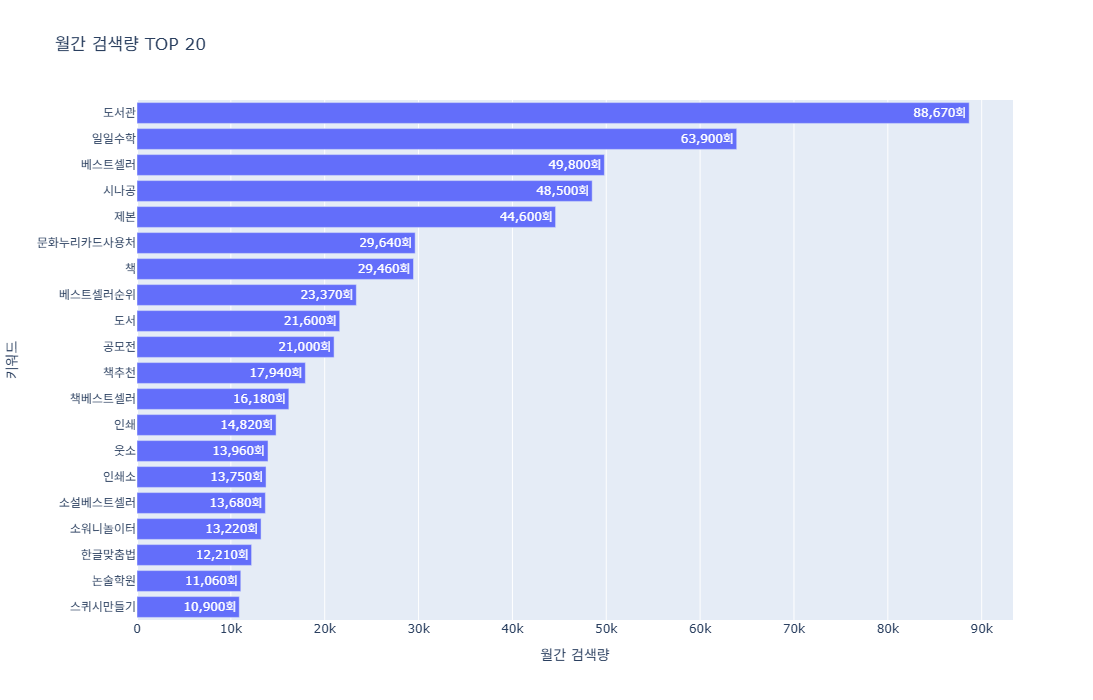

In [14]:
import plotly.express as px

fig = px.bar(
    top_search,
    x="search_total",
    y="keyword",
    title="월간 검색량 TOP 20",
    labels={
        "search_total": "월간 검색량",
        "keyword": "키워드"
    },
    text="search_total"
)

fig.update_layout(
    yaxis={
        "categoryorder": "total ascending"
    },
    height=700
)

fig.update_traces(
    texttemplate="%{text:,.0f}회"
)

fig.show()

In [11]:
top_search.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
23,도서관,9370.0,79300.0,7.3,40.9,0.09,0.06,높음,3,88670.0,48.2,10.567272,89.432728
279,일일수학,47600.0,16300.0,43.0,17.0,0.14,0.30,낮음,1,63900.0,60.0,74.491393,25.508607
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369
242,시나공,29200.0,19300.0,29.0,117.8,0.11,0.66,중간,3,48500.0,146.8,60.206186,39.793814
383,제본,10000.0,34600.0,183.8,438.9,1.93,1.33,중간,8,44600.0,622.7,22.421525,77.578475


In [15]:
top20_device = top_search.melt(
    id_vars = "keyword",
    value_vars=[
        "search_pc",
        "search_mobile"
    ],
    var_name="device",
    value_name="search_volume"
)

top20_device

# 전체 데이터의 탐색적 데이터 분석과정 (정제)
# 주요 인기 키워드 20위 선별
# 인기 키워드의 pc, mobile의 인기 정도 확인

,keyword,device,search_volume
0,도서관,search_pc,9370.0
1,일일수학,search_pc,47600.0
2,베스트셀러,search_pc,13400.0
3,시나공,search_pc,29200.0
4,제본,search_pc,10000.0
5,문화누리카드사용처,search_pc,4540.0
6,책,search_pc,6860.0
7,베스트셀러순위,search_pc,3870.0
8,도서,search_pc,8000.0
9,공모전,search_pc,9700.0


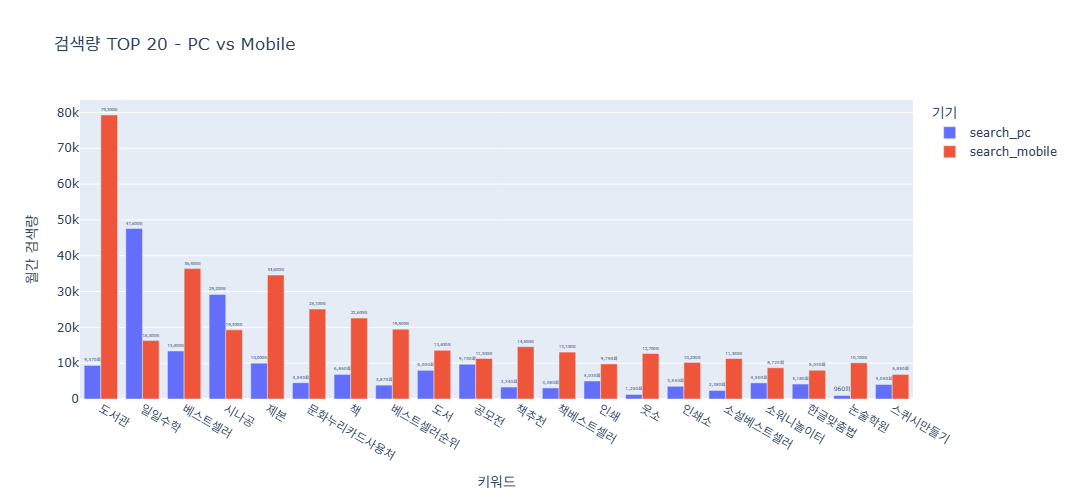

In [20]:
import plotly.express as px

fig = px.bar(
    top20_device,
    x="keyword",
    y="search_volume",
    title="검색량 TOP 20 - PC vs Mobile",
    color="device",
    barmode="group",
    labels={
        "search_volume": "월간 검색량",
        "keyword": "키워드",
        "device": "기기"
    },
    text_auto=True
    # text="search_volume"
)

fig.update_layout(
    width=1000,
    height=500
)

fig.update_traces(
    texttemplate="%{y:,.0f}회",
    textposition="outside",
    cliponaxis=False
)

fig.show()

In [ ]:
# 그로스 마케터
# 1) 네이버 연관키워드 EDA
# 2) 네이버 연관키워드 주요 키워드 20개 추출
# 3) 20개 키워드 PC, Mobile 편향 조사 : Mobile // PC : 수험생, 시험공부 관련 책
# 4) Mobile 중심으로 키워드 재분석

In [66]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10,21600.0,323.2,37.037037,62.962963
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10,4960.0,10.9,22.379032,77.620968
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10,29460.0,236.1,23.285811,76.714189
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763


In [21]:
mobile_keyword = df[df["search_total"] >= 1000].sort_values("mobile_ratio", ascending=False).head(20).copy()

In [22]:
mobile_keyword[
    ["keyword", "search_pc", "search_mobile", "mobile_ratio"]
].round(2)

,keyword,search_pc,search_mobile,mobile_ratio
423,말이야와친구들,150.0,3390.0,95.76
965,국어문제집,160.0,1750.0,91.62
360,논술학원,960.0,10100.0,91.32
633,독서학원,110.0,1110.0,90.98
495,웃소,1260.0,12700.0,90.97
325,문화누리사용처,330.0,3240.0,90.76
742,논술준비,130.0,1190.0,90.15
508,코믹스,250.0,2210.0,89.84
995,읽으면서바로써먹는,240.0,2120.0,89.83
23,도서관,9370.0,79300.0,89.43


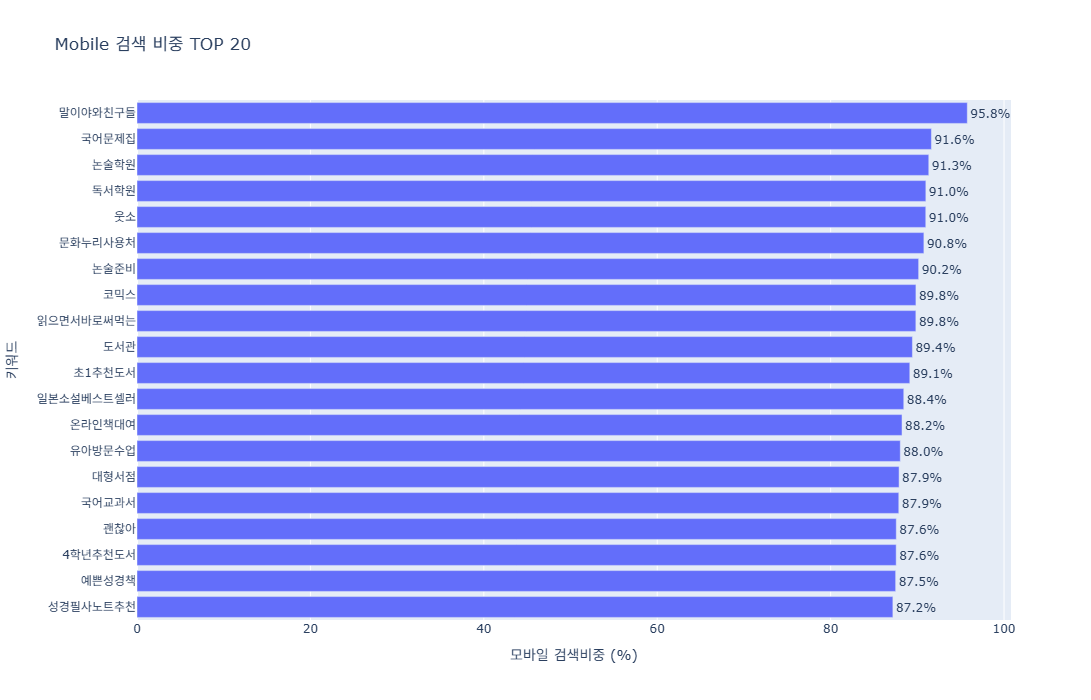

In [23]:
import plotly.express as px

fig = px.bar(
    mobile_keyword,
    x="mobile_ratio",
    y="keyword",
    title="Mobile 검색 비중 TOP 20",
    labels={
        "mobile_ratio": "모바일 검색비중 (%)",
        "keyword": "키워드"
    },
    hover_data=[
        "search_total",
        "search_mobile"
    ],
    # text_auto=True
    text="mobile_ratio"
)

fig.update_layout(
    yaxis={
        "categoryorder": "total ascending"
    },
    height=700
)

fig.update_traces(
    texttemplate="%{text:,.1f}%",
    textposition="outside"
)

fig.show()

In [ ]:
# 그로스 마케터
# 1) 네이버 연관키워드 EDA
# 2) 네이버 연관키워드 주요 키워드 20개 추출
# 3) 20개 키워드 PC, Mobile 편향 조사 : Mobile // PC : 수험생, 시험공부 관련 책
# 4) Mobile 중심으로 키워드 재분석 - 1 : 전체 검색량 1000건 이상 + 모바일 클릭률 내림차순 : 웃소, 국어, 논술, 독서, 일본베스트셀러, 온라인책대여
# 5) Mobile 중심으로 키워드 재분석 - 2 : 모바일 검색 500건 이상 + 모바일 클릭률 내림차순 :

In [75]:
df.describe()

,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,ad_count,search_total,click_total,pc_ratio,mobile_ratio
count,732.000000,885.000000,1000.00000,1000.000000,577.000000,713.000000,1000.000000,723.000000,1000.000000,723.000000,723.000000
mean,399.699454,879.254237,2.14070,11.852000,2.525234,2.761711,6.659000,1475.919779,13.992700,25.606997,74.393003
std,2286.124545,3787.780590,11.67392,67.833079,4.370142,3.090283,3.196707,5746.664269,77.396964,12.967154,12.967154
min,10.000000,10.000000,0.00000,0.000000,0.030000,0.040000,0.000000,20.000000,0.000000,2.500000,10.000000
25%,20.000000,30.000000,0.00000,0.000000,0.410000,0.580000,3.000000,90.000000,0.300000,16.507694,66.666667
50%,50.000000,120.000000,0.20000,0.900000,1.240000,1.670000,7.000000,260.000000,1.000000,23.076923,76.923077
75%,180.000000,460.000000,0.70000,3.800000,2.950000,3.760000,10.000000,825.000000,4.600000,33.333333,83.492306
max,47600.000000,79300.000000,183.80000,1462.400000,50.000000,25.000000,10.000000,88670.000000,1641.400000,90.000000,97.500000


In [24]:
top_ctr_mobile = df[df["search_mobile"] >= 500].sort_values("ctr_mobile", ascending=False).head(20).copy()

In [25]:
top_ctr_mobile

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
573,무협소설,1010.0,5170.0,49.7,623.4,5.25,12.97,높음,10,6180.0,673.1,16.343042,83.656958
508,코믹스,250.0,2210.0,6.3,238.4,2.73,11.69,중간,6,2460.0,244.7,10.162602,89.837398
293,문화누리카드온라인사용처,560.0,2420.0,33.4,244.4,6.25,10.57,높음,10,2980.0,277.8,18.791946,81.208054
973,온라인책대여,180.0,1350.0,7.7,127.7,4.54,10.15,중간,8,1530.0,135.4,11.764706,88.235294
51,책구매사이트,260.0,910.0,14.9,81.0,6.06,9.58,높음,10,1170.0,95.9,22.222222,77.777778
98,서점당일배송,50.0,680.0,2.3,58.9,4.43,9.18,높음,9,730.0,61.2,6.849315,93.150685
42,책구매,320.0,800.0,16.7,63.4,5.50,8.39,높음,10,1120.0,80.1,28.571429,71.428571
220,성경책구입,90.0,540.0,4.7,41.8,5.42,8.00,높음,7,630.0,46.5,14.285714,85.714286
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763
307,문화누리카드가맹점,690.0,3000.0,20.1,204.0,3.06,7.34,높음,10,3690.0,224.1,18.699187,81.300813


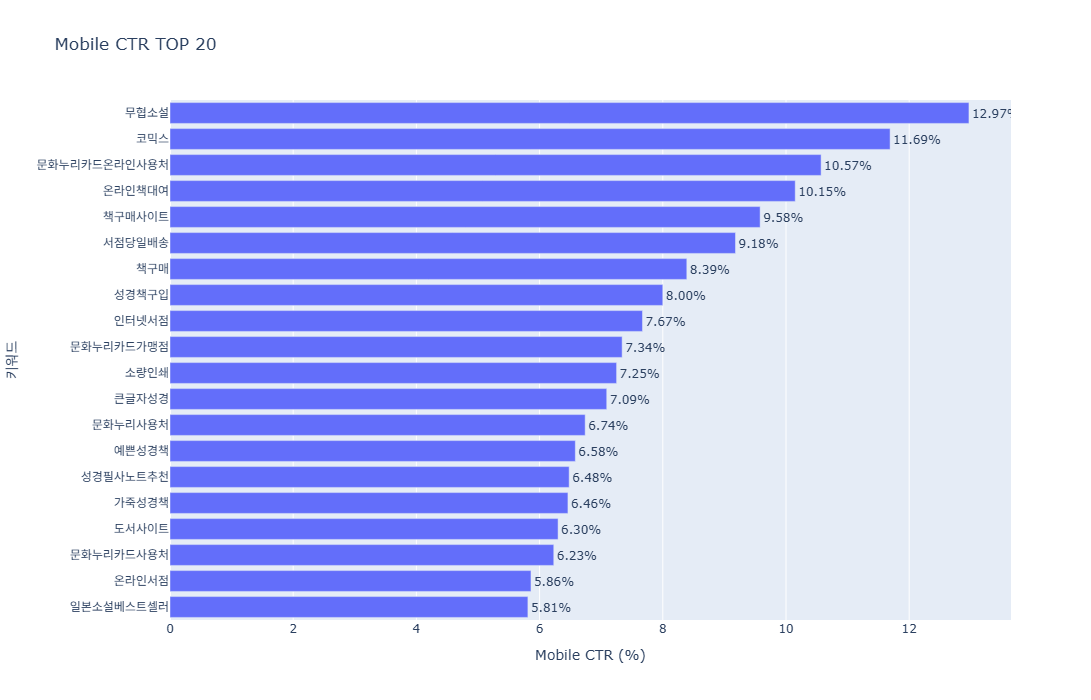

In [26]:
import plotly.express as px

fig = px.bar(
    top_ctr_mobile,
    x="ctr_mobile",
    y="keyword",
    title="Mobile CTR TOP 20",
    labels={
        "ctr_mobile": "Mobile CTR (%)",
        "keyword": "키워드"
    },
    hover_data=[
        "click_mobile",
        "search_mobile",
        "competition"
    ],
    # text_auto=True
    text="ctr_mobile"
)

fig.update_layout(
    yaxis={
        "categoryorder": "total ascending"
    },
    height=700
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.show()

In [ ]:
# 그로스 마케터
# 1) 네이버 연관키워드 EDA
# 2) 네이버 연관키워드 주요 키워드 20개 추출
# 3) 20개 키워드 PC, Mobile 편향 조사 : Mobile // PC : 수험생, 시험공부 관련 책
# 4) Mobile 중심으로 키워드 재분석 - 1 : 전체 검색량 1000건 이상 + 모바일 클릭률 내림차순 : 웃소, 국어, 논술, 독서, 일본베스트셀러, 온라인책대여
# 5) Mobile 중심으로 키워드 재분석 - 2 : 모바일 검색 500건 이상 + 모바일 클릭률 내림차순 : 일본베스트셀러, 온라인책대여, 성경 등 종교관련, 소량인쇄
# 6) PC 중심으로 키워드 분석 : PC 검색 500건 이상 + PC 클릭률 내림차순 : 소량인쇄, 도서순위, 도서검색 등 키워드 (모바일과는 살짝 다른 느낌)

In [27]:
top_ctr_pc = df[df["search_pc"] >= 500].sort_values("ctr_pc", ascending=False).head(20).copy()

In [28]:
top_ctr_pc

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
375,소량인쇄,1260.0,1010.0,75.8,68.6,6.33,7.25,높음,10,2270.0,144.4,55.506608,44.493392
293,문화누리카드온라인사용처,560.0,2420.0,33.4,244.4,6.25,10.57,높음,10,2980.0,277.8,18.791946,81.208054
573,무협소설,1010.0,5170.0,49.7,623.4,5.25,12.97,높음,10,6180.0,673.1,16.343042,83.656958
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763
393,인쇄업체,760.0,460.0,30.7,25.8,4.22,5.87,높음,10,1220.0,56.5,62.295082,37.704918
6,온라인서점,680.0,1490.0,26.7,83.4,4.19,5.86,높음,10,2170.0,110.1,31.336406,68.663594
273,문화누리카드사용처,4540.0,25100.0,179.0,1462.4,4.17,6.23,높음,10,29640.0,1641.4,15.317139,84.682861
373,포스터제작,2820.0,3280.0,84.7,116.2,3.15,3.76,높음,7,6100.0,200.9,46.229508,53.770492
307,문화누리카드가맹점,690.0,3000.0,20.1,204.0,3.06,7.34,높음,10,3690.0,224.1,18.699187,81.300813
159,교보문고베스트셀러순위,560.0,1830.0,14.2,92.9,2.67,5.44,중간,3,2390.0,107.1,23.430962,76.569038


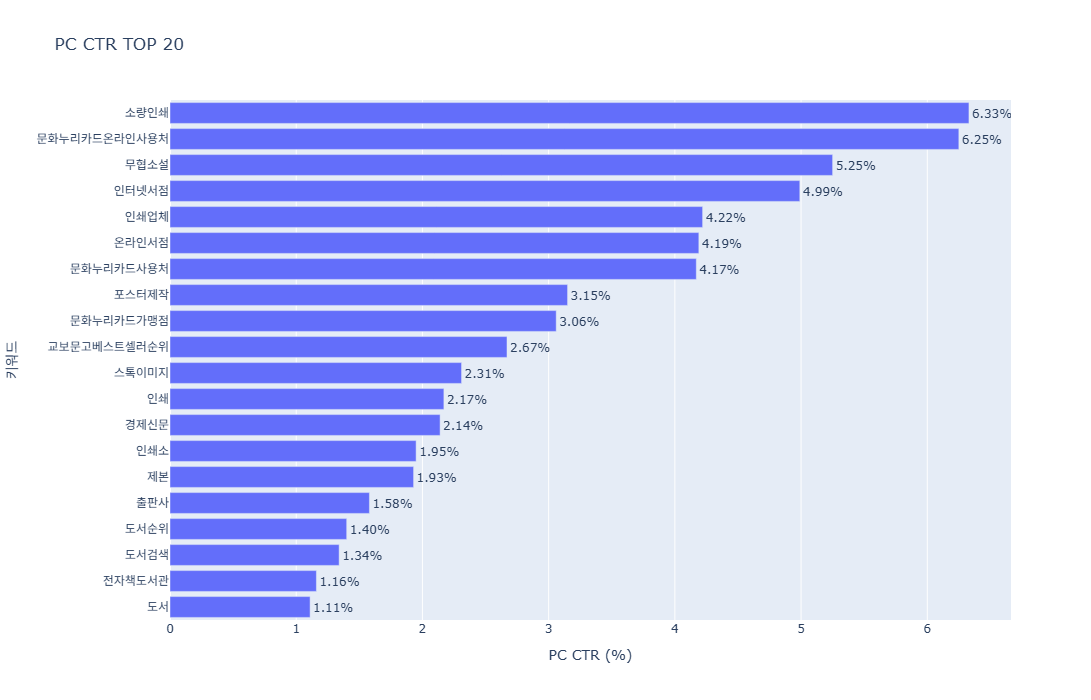

In [29]:
import plotly.express as px

fig = px.bar(
    top_ctr_pc,
    x="ctr_pc",
    y="keyword",
    title="PC CTR TOP 20",
    labels={
        "ctr_pc": "PC CTR (%)",
        "keyword": "키워드"
    },
    # text_auto=True
    text="ctr_pc"
)

fig.update_layout(
    yaxis={
        "categoryorder": "total ascending"
    },
    height=700
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.show()

In [ ]:
# 그로스 마케터
# 1) 네이버 연관키워드 EDA
# 2) 네이버 연관키워드 주요 키워드 20개 추출
# 3) 20개 키워드 PC, Mobile 편향 조사 : Mobile // PC : 수험생, 시험공부 관련 책
# 4) Mobile 중심으로 키워드 재분석 - 1 : 전체 검색량 1000건 이상 + 모바일 클릭률 내림차순 : 웃소, 국어, 논술, 독서, 일본베스트셀러, 온라인책대여
# 5) Mobile 중심으로 키워드 재분석 - 2 : 모바일 검색 500건 이상 + 모바일 클릭률 내림차순 : 일본베스트셀러, 온라인책대여, 성경 등 종교관련, 소량인쇄
# 6) PC 중심으로 키워드 분석 : PC 검색 500건 이상 + PC 클릭률 내림차순 : 소량인쇄, 도서순위, 도서검색 등 키워드 (모바일과는 살짝 다른 느낌)
# 7) 세부 데이터 상관관계 :
# - 검색량 & Mobile CTR : 검색량이 높은 키워드를 기반 컨텐츠 마케팅 : 검색량은 실제로 모바일 클릭률에 영향을 주지 못한다 (관계없음) -> 로그스케일 (최저~최대 분산 폭넓게)

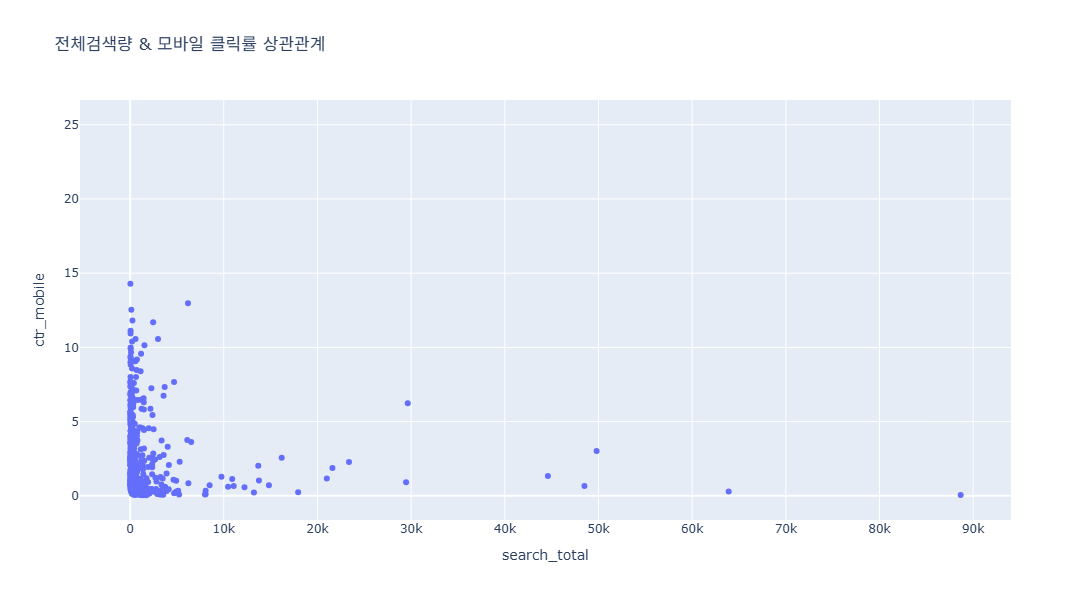

In [31]:
fig = px.scatter(
    df,
    x="search_total",
    y="ctr_mobile",
    title="전체검색량 & 모바일 클릭률 상관관계"
)

fig.update_layout(
    height=600
)

fig.show()

In [ ]:
# 전체 데이터의 범위가 너무 넓은 경우 = 해당 지표가 의미하는 바를 확인하기 어려운 부분이 있음
# 선형스케일(Linear Scale) : 물리적인 값의 차이만큼 간격을 일정하게 벌려놓은 지표
# 로그스케일(Log Scale) : 해당 값에 상용로그를 적용 = log10(값) = log10^3 = 3

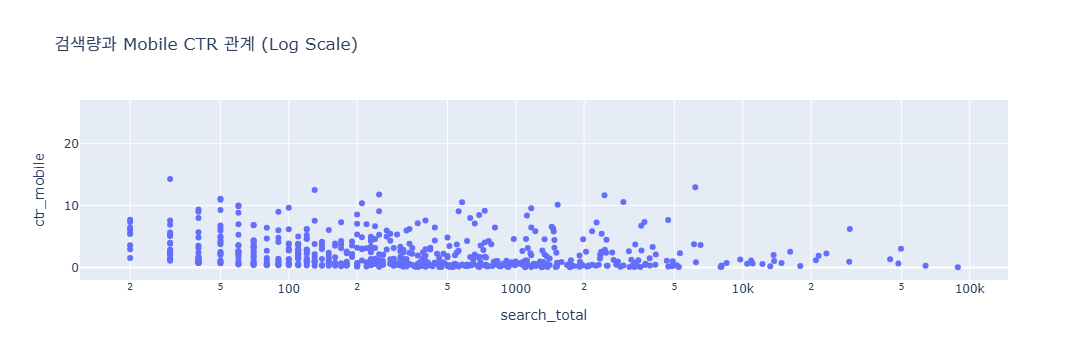

In [34]:
import plotly.express as px

fig = px.scatter(
    df,
    x="search_total",
    y="ctr_mobile",
    title="검색량과 Mobile CTR 관계 (Log Scale)",
    log_x=True
)

fig.show()

In [ ]:
# 그로스 마케터
# 1) 네이버 연관키워드 EDA
# 2) 네이버 연관키워드 주요 키워드 20개 추출
# 3) 20개 키워드 PC, Mobile 편향 조사 : Mobile // PC : 수험생, 시험공부 관련 책
# 4) Mobile 중심으로 키워드 재분석 - 1 : 전체 검색량 1000건 이상 + 모바일 클릭률 내림차순 : 웃소, 국어, 논술, 독서, 일본베스트셀러, 온라인책대여
# 5) Mobile 중심으로 키워드 재분석 - 2 : 모바일 검색 500건 이상 + 모바일 클릭률 내림차순 : 일본베스트셀러, 온라인책대여, 성경 등 종교관련, 소량인쇄
# 6) PC 중심으로 키워드 분석 : PC 검색 500건 이상 + PC 클릭률 내림차순 : 소량인쇄, 도서순위, 도서검색 등 키워드 (모바일과는 살짝 다른 느낌)
# 7) 세부 데이터 상관관계 :
# - 검색량 & Mobile CTR : 검색량이 높은 키워드를 기반 컨텐츠 마케팅 : 검색량은 실제로 모바일 클릭률에 영향을 주지 못한다 (관계없음) -> 로그스케일 (최저~최대 분산 폭넓게)
# - 경쟁정도 & Search : 경쟁 & 검색 -> 노출 기회 -> 검색 & 클릭 // 경쟁이 낮음에도 불구하고 검색을 많이하고, 클릭도 많이한 것이 있다면 => 이 것을 가지고 가성비 마케팅 가능
# 현재의 검색 키워드 가운데 84%는 이미 치열한 경쟁을 하고 있는 키워드 = 경쟁속에서의 마케팅 집행 비용 투입이 불가피하다

In [35]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10,21600.0,323.2,37.037037,62.962963
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10,4960.0,10.9,22.379032,77.620968
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10,29460.0,236.1,23.285811,76.714189
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763


In [41]:
competition_count = df["competition"].value_counts().reset_index()

competition_count

,competition,count
0,높음,842
1,중간,128
2,낮음,30


In [48]:
competition_ratio = df["competition"].value_counts(normalize=True).mul(100).reset_index()

competition_ratio

,competition,proportion
0,높음,84.2
1,중간,12.8
2,낮음,3.0


In [ ]:
#groupy 종류1

# campaign = ads.groupby("캠페인 이름", as_index=False).agg({
#     "지출 금액 (KRW)":"sum",
#     "노출":"count",
#     "링크 클릭":"mean",
#     "결과":"median",
# })

In [ ]:
#groupy 종류2

# ads_type = ads.groupby("광고 유형", as_index=False)[
#     ["지출 금액(KRW)","노출", "링크 클릭", "결과"]
# ].sum()

In [55]:
#groupy 종류3

competition_summary = df.groupby("competition", as_index=False).agg(
    keyword_count=("keyword", "count"),
    avg_search=("search_total", "mean"),
    median_search=("search_total", "median"),
    avg_ctr_mobile=("ctr_mobile", "mean")
).reset_index().round(2)

competition_summary

,index,competition,keyword_count,avg_search,median_search,avg_ctr_mobile
0,0,낮음,30,6389.09,460.0,1.89
1,1,높음,842,1277.04,250.0,2.63
2,2,중간,128,2295.12,265.0,3.68


In [56]:
# 그로스 마케터
# 1) 네이버 연관키워드 EDA
# 2) 네이버 연관키워드 주요 키워드 20개 추출
# 3) 20개 키워드 PC, Mobile 편향 조사 : Mobile // PC : 수험생, 시험공부 관련 책
# 4) Mobile 중심으로 키워드 재분석 - 1 : 전체 검색량 1000건 이상 + 모바일 클릭률 내림차순 : 웃소, 국어, 논술, 독서, 일본베스트셀러, 온라인책대여
# 5) Mobile 중심으로 키워드 재분석 - 2 : 모바일 검색 500건 이상 + 모바일 클릭률 내림차순 : 일본베스트셀러, 온라인책대여, 성경 등 종교관련, 소량인쇄
# 6) PC 중심으로 키워드 분석 : PC 검색 500건 이상 + PC 클릭률 내림차순 : 소량인쇄, 도서순위, 도서검색 등 키워드 (모바일과는 살짝 다른 느낌)
# 7) 세부 데이터 상관관계 :
# - 검색량 & Mobile CTR : 검색량이 높은 키워드를 기반 컨텐츠 마케팅 : 검색량은 실제로 모바일 클릭률에 영향을 주지 못한다 (관계없음) -> 로그스케일 (최저~최대 분산 폭넓게)
# - 경쟁정도 & Search : 경쟁 & 검색 -> 노출 기회 -> 검색 & 클릭 // 경쟁이 낮음에도 불구하고 검색을 많이하고, 클릭도 많이한 것이 있다면 => 이 것을 가지고 가성비 마케팅 가능
# > 현재의 검색 키워드 가운데 84%는 이미 치열한 경쟁을 하고 있는 키워드 = 경쟁속에서의 마케팅 집행 비용 투입이 불가피하다
# 1. 84% 정도의 높은 비율로 키워드의 경쟁정도가 심하다 
# 2. 검색량만 본다면, 경쟁정도가 낮은 키워드가 유리하다
# 3. 클릭률을 통한 유입을 생각한다면, 중간경쟁 정도가 좋다

In [58]:
# 낮음, 중간, 높음 = 비 정형 데이터를 정형데이터로 바꾸려고 함 => 1, 2, 3 *해당 과정을 feature engineering이라고 부름

competition_map = {
    "낮음": 1,
    "중간": 2,
    "높음": 3
}

df["competition_score"] = df["competition"].map(competition_map)

df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio,competition_score
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10,21600.0,323.2,37.037037,62.962963,3
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10,4960.0,10.9,22.379032,77.620968,3
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10,29460.0,236.1,23.285811,76.714189,3
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369,3
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763,3


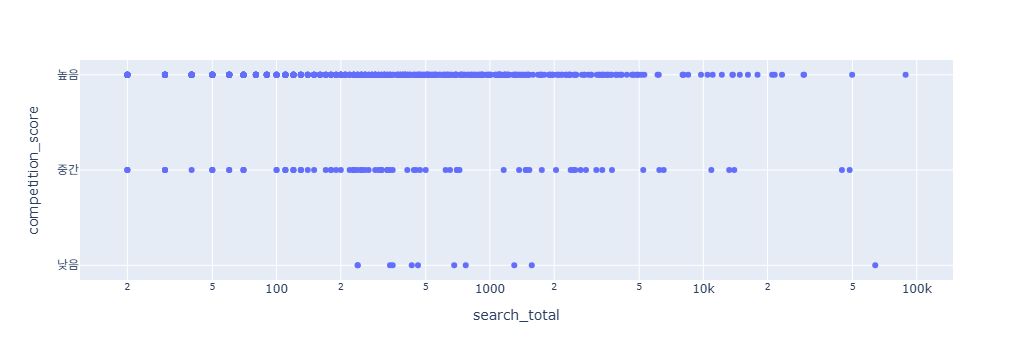

In [64]:
fig = px.scatter(
    df,
    x="search_total",
    y="competition_score",
    log_x=True,
    hover_data=["keyword", "ad_count", "ctr_mobile"]
)

fig.update_xaxes(
    # type="log"
)

fig.update_yaxes(
    tickvals=[1,2,3],
    ticktext=["낮음", "중간", "높음"]
)

fig.show()

In [ ]:
# 최소-최대 정규화 (Min-Max Normalization)
# 만약 범위가 1~100만원이 나왔다면 넓이가 너무 크니까 > *모든 값을 0~1로 만들기 : (현재값-최소값) / (최대값-최소값)

# 전체 검색량을 1~0까지 만들어놓고
# 모바일 클릭률을 1~0까지
# 범위가 너무 넓은 값들을 쉽게 식별하기 위한 목적
# 가중치를 부여 : 소비자들에게 중요한 지표(가족단위 50%, 동물 30%, 할인 20%)

df.describe()

In [65]:
df["search_score"] = (df["search_total"] - df["search_total"].min()) / (df["search_total"].max() - df["search_total"].min())
df["ctr_score"] = (df["ctr_mobile"] - df["ctr_mobile"].min()) / (df["ctr_mobile"].max() - df["ctr_mobile"].min())

In [66]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio,competition_score,search_score,ctr_score
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10,21600.0,323.2,37.037037,62.962963,3,0.243429,0.073718
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10,4960.0,10.9,22.379032,77.620968,3,0.055725,0.010016
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10,29460.0,236.1,23.285811,76.714189,3,0.332092,0.034856
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369,3,0.561534,0.119391
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763,3,0.052679,0.305689


In [67]:
competition_map = {
    "낮음": 1,
    "중간": 2,
    "높음": 3
}

df["competition_opportunity"] = (4 - df["competition_score"]) / 3

In [68]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio,competition_score,search_score,ctr_score,competition_opportunity
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10,21600.0,323.2,37.037037,62.962963,3,0.243429,0.073718,0.333333
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10,4960.0,10.9,22.379032,77.620968,3,0.055725,0.010016,0.333333
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10,29460.0,236.1,23.285811,76.714189,3,0.332092,0.034856,0.333333
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369,3,0.561534,0.119391,0.333333
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763,3,0.052679,0.305689,0.333333


In [69]:
df["opportunity_score"] = df["search_score"] * 0.5 + df["ctr_score"] * 0.3 + df["competition_opportunity"] * 0.2

In [71]:
df.head()

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio,competition_score,search_score,ctr_score,competition_opportunity,opportunity_score
0,도서,8000.0,13600.0,84.0,239.2,1.11,1.88,높음,10,21600.0,323.2,37.037037,62.962963,3,0.243429,0.073718,0.333333,0.210497
1,독서,1110.0,3850.0,0.5,10.4,0.05,0.29,높음,10,4960.0,10.9,22.379032,77.620968,3,0.055725,0.010016,0.333333,0.097534
2,책,6860.0,22600.0,44.1,192.0,0.68,0.91,높음,10,29460.0,236.1,23.285811,76.714189,3,0.332092,0.034856,0.333333,0.243170
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369,3,0.561534,0.119391,0.333333,0.383251
4,인터넷서점,1650.0,3040.0,78.3,218.8,4.99,7.67,높음,10,4690.0,297.1,35.181237,64.818763,3,0.052679,0.305689,0.333333,0.184713


In [73]:
opportunity = df.sort_values("opportunity_score", ascending=False).head(20).copy()

In [74]:
opportunity # 지금 마케팅을 하면 괜찮을 법한 키워드를 추출(경쟁도 + 모바일 클릭률 + 전체검색량)

,keyword,search_pc,search_mobile,click_pc,click_mobile,ctr_pc,ctr_mobile,competition,ad_count,search_total,click_total,pc_ratio,mobile_ratio,competition_score,search_score,ctr_score,competition_opportunity,opportunity_score
23,도서관,9370.0,79300.0,7.3,40.9,0.09,0.06,높음,3,88670.0,48.2,10.567272,89.432728,3,1.000000,0.000801,0.333333,0.566907
279,일일수학,47600.0,16300.0,43.0,17.0,0.14,0.30,낮음,1,63900.0,60.0,74.491393,25.508607,1,0.720587,0.010417,1.000000,0.563418
242,시나공,29200.0,19300.0,29.0,117.8,0.11,0.66,중간,3,48500.0,146.8,60.206186,39.793814,2,0.546870,0.024840,0.666667,0.414220
383,제본,10000.0,34600.0,183.8,438.9,1.93,1.33,중간,8,44600.0,622.7,22.421525,77.578475,2,0.502876,0.051683,0.666667,0.400276
3,베스트셀러,13400.0,36400.0,118.6,1031.9,0.93,3.02,높음,10,49800.0,1150.5,26.907631,73.092369,3,0.561534,0.119391,0.333333,0.383251
273,문화누리카드사용처,4540.0,25100.0,179.0,1462.4,4.17,6.23,높음,10,29640.0,1641.4,15.317139,84.682861,3,0.334123,0.247997,0.333333,0.308127
779,사진동화책,10.0,20.0,0.7,3.9,6.07,14.29,중간,6,30.0,4.6,33.333333,66.666667,2,0.000113,0.570913,0.666667,0.304664
508,코믹스,250.0,2210.0,6.3,238.4,2.73,11.69,중간,6,2460.0,244.7,10.162602,89.837398,2,0.027524,0.466747,0.666667,0.287119
76,도서새벽배송,10.0,120.0,1.5,14.8,10.82,12.53,중간,5,130.0,16.3,7.692308,92.307692,2,0.001241,0.500401,0.666667,0.284074
83,책새벽배송,10.0,240.0,0.5,28.2,4.77,11.81,중간,6,250.0,28.7,4.000000,96.000000,2,0.002594,0.471554,0.666667,0.276097


In [75]:
# 형태소분석 = "나는 배가 정말 고프다" => 명사, 조사, 동사 등 "나는", "배가", "정말", "고프다"

In [77]:
!pip install Kiwipiepy

In [ ]:
# 과거에는 형태소 분석 시, konlpy를 사용 (JAVA 기반)
# 최근에는 KIWI(한국어 지능형 단어 식별기)를 많이 사용 => 한국어 단어를 지능적으로 식별할 수 있도록 돕는 모듈!

In [82]:
from kiwipiepy import Kiwi
from collections import Counter

kiwi = Kiwi(model_type="none") # 양자알고리즘을 사용하지 않겠다 = 일반 모드를 쓰겠다
# 모드가 2개 : 고성능, 고효율 모드(GPU를 사용한 양자알고리즘 방식)가 있고 일반 모드가 있음

word_list = []

for keyword in df["keyword"].dropna():
    tokens = kiwi.tokenize(str(keyword))

    for token in tokens :
        if token.tag in ["NNG", "NNP"] :
            if len(token.form) >= 2 :
                word_list.append(token.form)
word_counts = Counter(word_list)

# list comprehension 기법
words = [word for word, count in word_counts.most_common(20)]

words

# 주요 단어 출현 및 빈도수

['도서',
 '독서',
 '초등',
 '추천',
 '논술',
 '베스트셀러',
 '구독',
 '소설',
 '전자책',
 '온라인',
 '성경',
 '서점',
 '사이트',
 '국어',
 '유아',
 '순위',
 '무료',
 '구매',
 '초등학생',
 '인터넷']

In [ ]:
NNG : 일반명사 ex) 학교, 컴퓨터 
NNP : 고유명사 ex) 서울, 부산, 강남
NP : 대명사 ex) 나, 너
NR : 의존명사 ex) 것, 수
NNB : 숫자
SN : 외국어
MM : 관형사 ex) 새, 모든
EC : 연결어미 ex) 고, 면
VA : 형용사
MAG : 일반 부사
XSN : 명사 파생 접미사 ex) ~들, ~님
XR : 어근 ex) 깨끗, 시원
XPN : 체언 접두사 ex) 맨손 에서 '맨'
XSA : 형용사 파생 접미사 ex) 자연스럽다 에서 '스럽'
JKG : 관형격 조사 ex) 나의책 에서 '의'
ETN : 명사형 전성 어미 ex) 먹기 에서 '먹'
ETM : 관형형 전성 어미 ex) 먹는 사람 에서 '는'

In [92]:
intent_keywords = {

    # 1. 인기 및 순위 검색
    "Ranking": [
        "베스트셀러", "베스트", "순위", "랭킹",
        "판매순위", "인기도서", "인기책",
        "인기소설", "인기순위", "스테디셀러",
        "인기", "핫한책", "top10", "top100",
        "이달의책", "올해의책"
    ],

    # 2. 추천 및 도서 선택
    "Recommendation": [
        "추천", "필독서", "권장도서",
        "읽을만한책", "읽어야할책",
        "꼭읽어야할책", "좋은책",
        "인생책", "재미있는책",
        "입문서", "추천목록",
        "추천도서", "책추천", "도서추천",
        "추천책", "추천서적"
    ],

    # 3. 구매 및 가격 비교
    "Purchase": [
        "구매", "구입", "주문", "판매",
        "가격", "할인", "최저가",
        "특가", "쿠폰", "적립",
        "배송", "새벽배송", "당일배송",
        "무료배송", "해외배송",
        "쇼핑", "쇼핑몰", "서점",
        "문고", "책방", "도매",
        "중고", "헌책", "매입",
        "책사는", "책사기", "책파는",
        "구매대행", "가격비교",
        "선물", "이벤트", "정가"
    ],

    # 4. 열람, 대여 및 구독
    "Access": [
        "도서관", "대여", "렌탈",
        "대출", "빌리기", "빌려",
        "무료책", "무료도서",
        "무료독서", "무료서적",
        "무료보기", "무료읽기",
        "책보기", "책읽기",
        "책보는곳", "다운로드",
        "전자책", "이북", "ebook",
        "e-book", "e북", "오디오북",
        "구독", "정기구독",
        "구독서비스", "무제한",
        "전자서점", "독서사이트",
        "독서어플", "독서앱",
        "책읽기프로그램"
    ],

    # 5. 도서 정보 및 탐색
    "Information": [
        "리뷰", "후기", "줄거리",
        "작가", "저자", "출판사",
        "내용", "목차", "서평",
        "독후감", "요약", "해설",
        "책소개", "도서정보",
        "책정보", "검색", "찾기",
        "평점", "감상문",
        "독서록", "독서감상문",
        "책종류", "잡지종류",
        "도서사이트", "책사이트"
    ],

    # 6. 신간 및 출간 정보
    "NewRelease": [
        "신간", "신작", "신규도서",
        "새로나온책", "새로나온도서",
        "최신도서", "최신책",
        "최신서적", "출간예정",
        "신간서적", "신간책",
        "출간", "발행"
    ],

    # 7. 교육, 학습 및 자격증
    "Education": [
        "교육", "학습", "교재",
        "문제집", "기출", "시험",
        "자격증", "자격검정",
        "국가고시", "임용",
        "수능", "입시", "수행평가",
        "초등", "중등", "고등",
        "중학생", "고등학생",
        "유아", "어린이", "청소년",
        "학생", "학원", "과외",
        "방문수업", "방문교육",
        "독서지도", "독서교육",
        "독서논술", "논술",
        "문해력", "독해력",
        "어휘", "한글", "수학",
        "과학탐구", "학습지",
        "독서활동지", "독후활동",
        "독서교실", "독서수업",
        "공부", "강의", "실전문제"
    ],

    # 8. 독서 활동 및 커뮤니티
    "Community": [
        "독서모임", "독서클럽",
        "북클럽", "독서토론",
        "글쓰기모임", "독서활동",
        "독서프로그램", "북러닝",
        "독서캠프", "독서습관",
        "독서챌린지", "독서기록",
        "독서일기", "독서노트",
        "책모임", "북토크",
        "작가와의만남", "토론",
        "독서동아리"
    ],

    # 9. 출판, 집필 및 제작
    "Publishing": [
        "출판", "집필", "책쓰기",
        "글쓰기", "소설쓰기",
        "자서전쓰기", "전자책쓰기",
        "전자책제작", "이북제작",
        "그림책제작", "책제작",
        "책발간", "발간비용",
        "인쇄", "인쇄소",
        "인쇄업체", "제본",
        "재본", "양장제본",
        "하드커버", "스프링책자",
        "책자", "표지",
        "편집", "인디자인",
        "기획출판", "소량인쇄",
        "대필", "작가채용",
        "원고", "출판계약"
    ],

    # 10. 도서 장르 및 주제
    "GenreTopic": [
        "소설", "에세이", "시집",
        "문학", "인문학", "철학",
        "역사", "경제", "경영",
        "심리학", "과학", "예술",
        "미술", "종교", "기독교",
        "불교", "성경", "육아",
        "동화", "전래동화",
        "만화", "웹툰", "잡지",
        "자기계발", "추리",
        "스릴러", "판타지",
        "로맨스", "SF",
        "여행", "요리", "건강",
        "재테크", "부동산",
        "컴퓨터", "프로그래밍",
        "IT", "외국어", "영어",
        "한국소설", "해외도서",
        "원서", "전집", "그림책"
    ],

    # 11. 도서 서비스 및 플랫폼
    "Platform": [
        "교보문고", "YES24",
        "예스24", "알라딘",
        "인터파크", "영풍문고",
        "리디", "리디북스",
        "밀리의서재", "윌라",
        "크레마", "킨들",
        "아마존", "네이버책",
        "북모닝", "샘터",
        "문학동네", "창작과비평",
        "SAM프리미엄",
        "SAM무제한",
        "문화누리카드",
        "문화누리"
    ],

    # 12. 일반 도서 및 독서 키워드
    "General": [
        "도서", "독서", "책",
        "서적", "book", "북",
        "읽기", "읽는법",
        "읽는방법"
    ]
}

In [101]:
def find_matching_intents(keyword) :
    keyword = str(keyword).lower()

    matched = list()
    
    for intent, keywords in intent_keywords.items() :
        if any(word.lower() in keyword for word in keywords) :
            matched.append(intent)
            
    return matched

df["matched_intents"] = df["keyword"].apply(find_matching_intents)

df["match_count"] = df["matched_intents"].apply(len)

df[["keyword", "matched_intents", "match_count"]].head(20)

print("미분류 키워드:", (df["matched_count"] == 0).sum())
print("복수매칭 키워드:",(df["matched_count"] >= 2).sum())
print("전체 키워드 수:", len(df))

미분류 키워드: 141
복수매칭 키워드: 494
전체 키워드 수: 1000


In [103]:
def classify_intent(keyword) : 
    keyword = str(keyword)

    for intent, words in intent_keywords.items() :
        for word in words :
            if word.lower() in keyword.lower() :
                return intent
    return "Others"

In [104]:
df["intent"] = df["keyword"].apply(classify_intent)

In [105]:
intent_summary = df.groupby("intent").agg(
    keyword_count=("keyword", "count"),
    total_search=("search_total", "sum"),
    avg_search=("search_total", "mean"),
    avg_ctr_mobile=("ctr_mobile", "mean")
).reset_index().sort_values("total_search", ascending=False).round(2)

intent_summary

,intent,keyword_count,total_search,avg_search,avg_ctr_mobile
7,Others,141,217640.0,2290.95,2.02
2,Education,228,158750.0,986.02,1.97
11,Ranking,75,138250.0,2513.64,2.08
0,Access,102,111270.0,1766.19,3.79
12,Recommendation,80,99560.0,1382.78,1.04
9,Publishing,33,87250.0,3490.00,2.67
3,General,73,85110.0,1702.20,1.84
4,GenreTopic,100,55400.0,719.48,3.31
8,Platform,7,40040.0,5720.00,7.18
5,Information,33,31490.0,1049.67,1.60


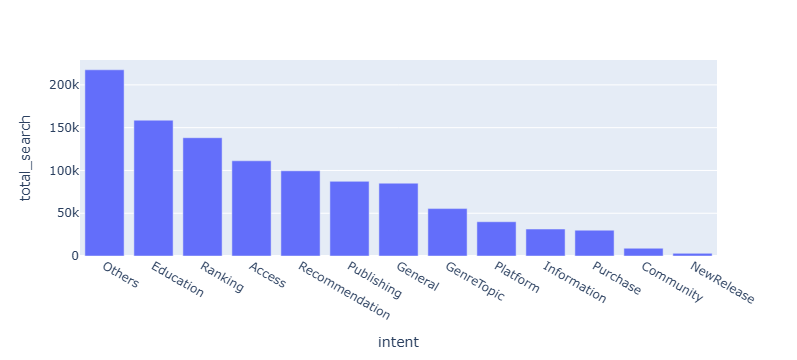

In [106]:
fig = px.bar(
    intent_summary,
    x="intent",
    y="total_search"
)

fig.show()

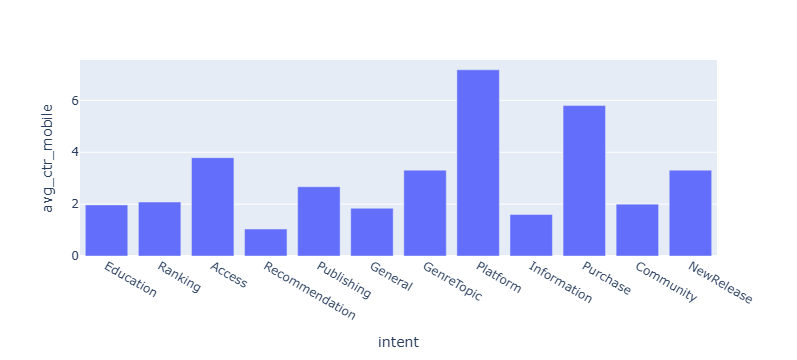

In [108]:
fig = px.bar(
    intent_summary[intent_summary["intent"] != "Others"],
    x="intent",
    y="avg_ctr_mobile"
)

fig.show()